Données de la base GDELT cloud et comparaison à l'inactivité et à la population en QPV

Avant de pouvoir explorer ces données, il faut importer quelques modules, et bien sûr les données, en utilisant le code suivant : 

In [1]:
## Importation des modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import json, s3fs

np.random.seed(123)

## Importation des données
fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})
CACHE = "vgounot/diffusion"

with fs.open(f"{CACHE}/gcloud_emeutes_all.json", "r", encoding="utf-8") as f:
    body = json.load(f)

Tout d'abord, il s'agit de nettoyer le jeu de données à notre disposition. En effet, après plusieurs essais et différentes cartes, nous avons rencontré différents types de données qu'il est souhaitable d'éliminer : 
     - Des émeutes dont la localisation n'est pas précisée, et qui se retrouvent toutes au même endroit dans la Creuse
     - Des émeutes qui n'ont pas eu lieu en France (une donnée à Barcelone)
     - Des émeutes en Outre-mer, retirées par souci de simplicité pour réaliser les cartes ensuite
Nous avons donc dû retirer douze lignes à la base de données initiale afin de simplifier la réalisation de la carte, et de ne pas fausser les analyses, notamment lorsque l'on regarde le nombre d'émeutes à l'échelle départementale (qui donnait alors la Creuse deuxième derrière Paris, alors qu'en réalité, il n'y a pas eu d'émeutes en Creuse).
De plus, le format des données a été un défi. En effet, le fichier json comportait des imbrications, rendant une extraction des données en deux temps, et une sélection des données à extraire. En effet, nous avons laissé certaines colonnes avec des données sous la forme de dictionnaires car elles ne nous étaient pas utiles, et nous avons extrait des dictionnaires uniquement les données qui nous intéressaient, à savoir latitude, longitude, localisation et pays, les deux derniers servant au nettoyage.
Le nettoyage se fait avec le code ci-après : 

In [2]:
data = pd.DataFrame(body) #read_json ne fonctionne pas car le json est "imbriqué" donc je crée une dataframe qui garde les dictionnaires de second niveau

data["lat"] = data["geo"].apply(lambda x: x["latitude"])
data["long"] = data["geo"].apply(lambda x: x["longitude"]) 
data["pays"] = data["geo"].apply(lambda x: x["country"])
data["loc"] = data["geo"].apply(lambda x: x["location"])
#On utilise la fonction apply pour appliquer une fonction à chaque élément d'une colonne
#On a maintenant deux colonnes qui nous donnent la localisation exacte des émeutes

## Nettoyage préalable

#On retire les données manquantes si jamais il y en a (et seulement si c'est la latitude ou la longitude qui manque)
data = data.dropna(subset=["lat", "long"])
#On retire aussi les Outre-mer sinon on aura des points partout dans le monde et ce sera illisible
data = data[(data["lat"]>=41.3)&(data["lat"]<=51.2)&(data["long"]>=-5.2)&(data["long"]<=9.7)]

data = data[data["pays"]=="France"] #On a remarqué un point un Espagne que l'on retire
data = data.dropna(subset=["loc"]) #On retire aussi les points non précis qui atterrissent tous au même endroit dans la Creuse

La première étape pour utiliser ces données a été de localiser ces données sur une carte, afin de vérifier leur bonne répartition sur le territoire français, et afin d'avoir une première idée des lieux des émeutes.
Il en ressort que, dans la grande majorité des cas, les émeutes ont lieu dans des grandes villes et notamment dans des préfectures (ou dans des sous-préfectures dans de plus rares cas). On peut aisément l'observer sur la carte ci-dessous : 

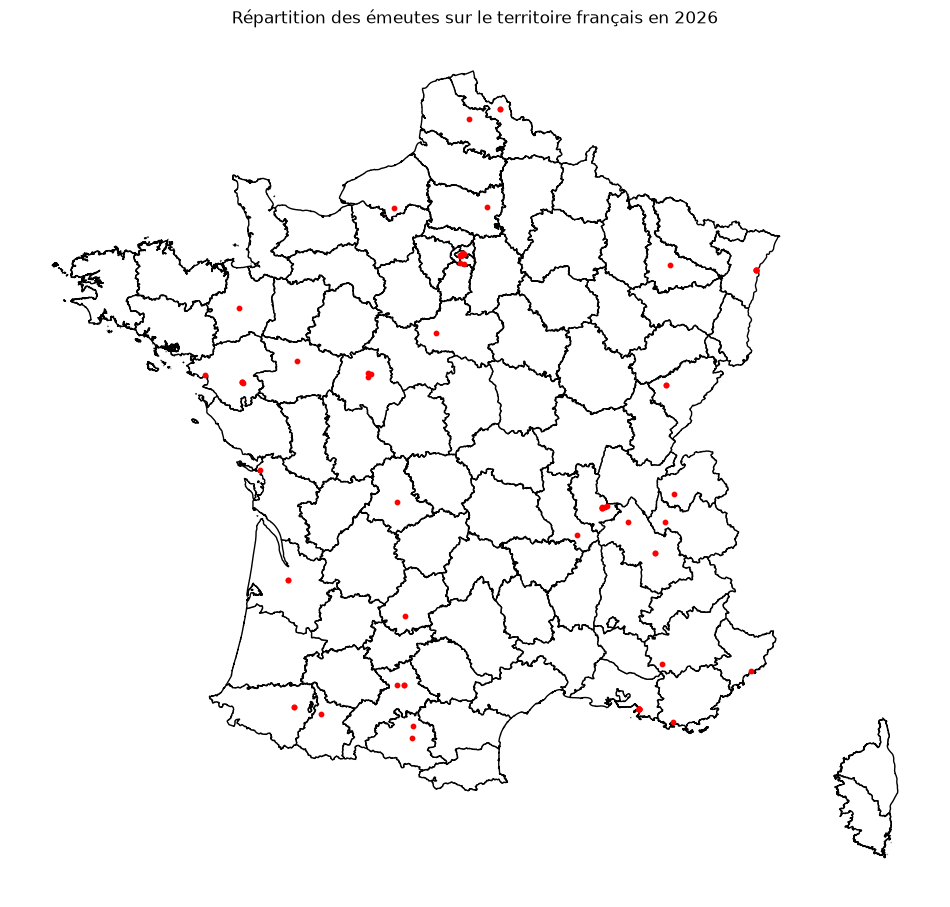

In [3]:
## Importation du fond de carte

url_fond_de_carte = ("https://minio.lab.sspcloud.fr/projet-cartiflette/production/"
       "provider=IGN/dataset_family=ADMINEXPRESS/"
       "source=EXPRESS-COG-CARTO-TERRITOIRE/year=2022/"
       "administrative_level=DEPARTEMENT/crs=4326/FRANCE_ENTIERE=France/"
       "vectorfile_format=geojson/territory=metropole/simplification=50/raw.geojson")

departements = gpd.read_file(url_fond_de_carte)
departements = departements[~departements["INSEE_DEP"].str.startswith("97")] 
#On retire les Outre-mer sinon la carte ne va ressembler à rien
departements = departements.to_crs(2154) #On passe en projection Lambert 93

## Création des points

points = gpd.GeoDataFrame(data, geometry=gpd.points_from_xy(data["long"], data["lat"]), crs=4326)
points = points.to_crs(2154) #On passe en projection Lambert 93

## Projection des points sur la carte

#Ici, je ne vois pas comment faire la jointure. On va donc superposer le fond de carte et les points
fig, ax = plt.subplots(figsize=(12,12))
departements.plot(ax=ax, color="white", edgecolor="black")
ax.set_axis_off()
ax.set_title("Répartition des émeutes sur le territoire français en 2026")
points.plot(ax=ax, color="red", markersize=10, legend=True, legend_kwds={"label": "Emeutes"})
plt.show()


Pour cette carte, la projection choisie est la projection Lambert 93. En effet, c'est celle qui était préconisée par le cours pour représenter la France car c'est la projection généralement utilisée pour ce genre d'usage. 

On peut ensuite agréger ces données au niveau du département en comptant le nombre d'émeutes par département depuis mars 2026. On obtient alors une nouvelle carte : 

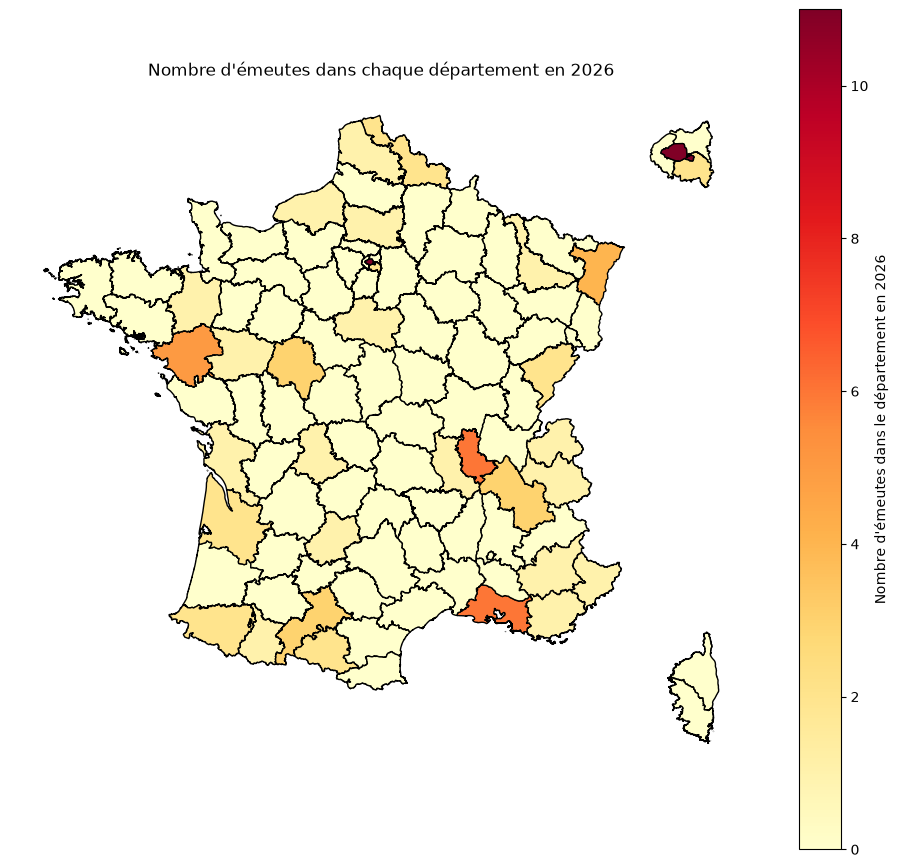

In [4]:
## Agrégation des émeutes par département

emeutes_département = gpd.sjoin(points, departements[["INSEE_DEP", "geometry"]], how="left", predicate="within")
# Cela permet d'attribuer un département à chaque de la carte
emeutes_département = emeutes_département.dropna(subset=["INSEE_DEP"])
# Il y a un point en dehors de la France sur la carte précédente, donc je préfère retirer la donnée pour la suite

émeutes_agrégé = emeutes_département["INSEE_DEP"].value_counts()
#On compte le nombre de fois où chaque département apparaît pour avoir le nombre d'événements récents par départements

carte2 = departements.merge(émeutes_agrégé, on="INSEE_DEP", how="left")
carte2["count"] = carte2["count"].fillna(0)
#Lorsque la valeur de count n'a pas été trouvée, c'est qu'il n'y a pas eu d'émeutes

petite_couronne = carte2[carte2["INSEE_DEP"].isin(["75", "92", "93", "94"])]

variable = "count"

vmin = carte2["count"].min()
vmax = carte2["count"].max()

fig = plt.figure(figsize=(16,10))

ax1 = fig.add_axes([0.03, 0.08, 0.58, 0.84])
ax2 = fig.add_axes([0.35, 0.65, 0.20, 0.25])

graphe2 = carte2.plot(column=variable, ax=ax1, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black", legend=True, legend_kwds={"label" : "Nombre d'émeutes dans le département en 2026"})
petite_couronne.plot(column=variable, ax=ax2, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black")
graphe2.set_axis_off()
graphe2.set_title("Nombre d'émeutes dans chaque département en 2026")
xmin, ymin, xmax, ymax = petite_couronne.total_bounds
ax2.set_xlim(xmin-50000, xmax+50000)
ax2.set_ylim(ymin-50000, ymax+50000)
ax2.set_axis_off()
plt.show()


Grâce à cette carte, on peut confirmer notre intuition de l'autre carte : c'est bien là où se trouvent les grandes villes qu'il y a le plus d'émeutes. En effet, les départements les plus foncés sur cette carte sont Paris (75), les Bouches-du-Rhône (13 - Marseille), le Rhône (69 - Lyon), mais aussi la Loire-Atlantique (44 - Nantes) et le Bas-Rhin (67 - Strasbourg). A l'inverse, les départements ruraux sont en général plus clairs, ce qui signifie qu'il y a moins d'émeutes dans ces départements, comme par exemple la Haute-Loire (43) ou le Cantal (15) qui n'ont pas connu d'émeutes depuis mars 2026. 
Ayant des données à l'échelle des départements sur l'inactivité chez les jeunes et la population résident en QPV, nous allons maintenant pouvoir comparer cette répartition géographique des émeutes aux données. 

Données sur l'inactivité chez les 15-24 ans et sur la part de la population vivant en QPV

Avant de comparer toutes nos données, on peut essayer de se familiariser avec ces nouvelles données. Elles sont disponibles sur le site de l'Observatoire des Territoires. Les données sur l'inactivité datent de 2023 et celles sur les QPV (Quartiers Prioritaires de la Ville) de 2024. Nous allons pouvoir visualiser ces données sur des cartes pour commencer. Commençons par les données sur l'inactivité. Nous avons, comme pour les émeutes, retiré les données sur les Outre-mer afin de se concentrer sur la métropole et de faciliter la création de la carte. Il nous a également fallu calculer le taux d'inactivité chez les jeunes pour chaque département, car nous n'avions de données que sur le taux d'activité. Il suffit de calculer le complément à 100 du taux d'activité. Ce taux d'inactivité se retrouve donc sur la carte ci-dessous : 

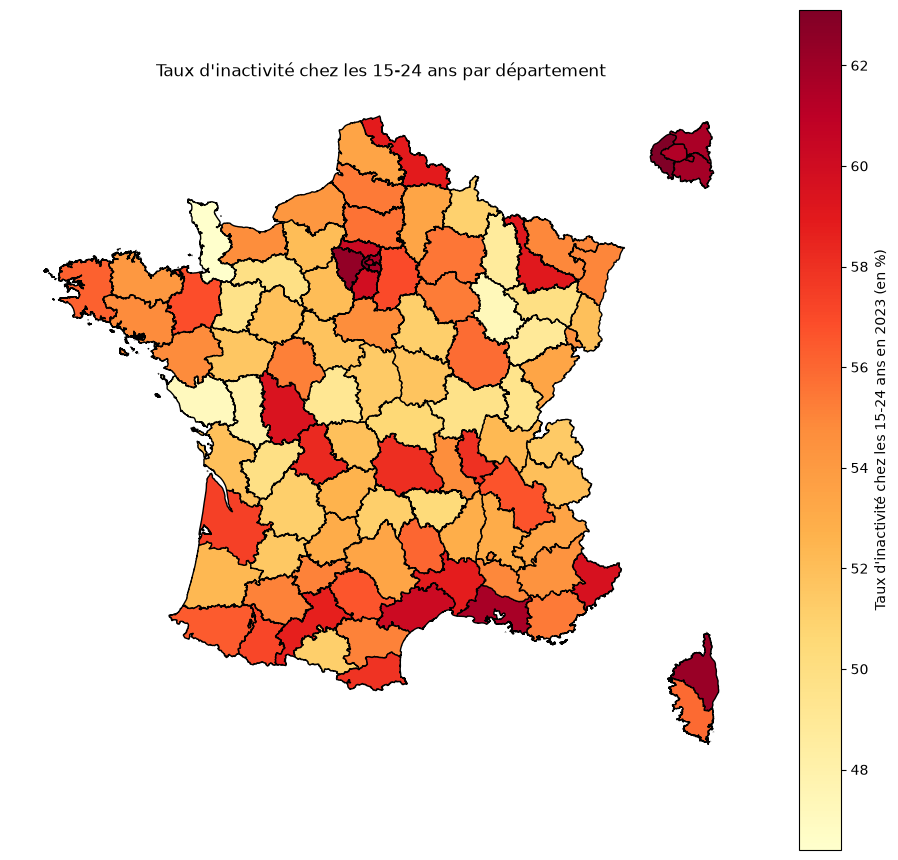

In [5]:
## Importation du jeu de données

data_inactivité=pd.read_csv("/home/onyxia/Projet_Python_2A/inactivité_data/Départements/inactivité_jeunes_departement.csv", skiprows=2, sep=";", dtype={"Code":str})
#Le code est ici mis en string pour que l'on puisse retirer les Outre-mer dont le code commence par 97

##  Nettoyage

data_inactivité = data_inactivité[~data_inactivité["Code"].str.startswith("97")] #On retire les Outre-mer pour éviter des problèmes avec la carte
data_inactivité["Taux d'activité des 15-24 ans 2023"] = data_inactivité["Taux d'activité des 15-24 ans 2023"].astype(float)
#On s'assure que le type des données est numérique pour que l'on puisse faire des calculs dessus

##  Calcul du taux d'inactivité

data_inactivité["Taux d'inactivité chez les jeunes"] = 100-data_inactivité["Taux d'activité des 15-24 ans 2023"]

##  Création d'une carte 

url = ("https://minio.lab.sspcloud.fr/projet-cartiflette/production/"
       "provider=IGN/dataset_family=ADMINEXPRESS/"
       "source=EXPRESS-COG-CARTO-TERRITOIRE/year=2022/"
       "administrative_level=DEPARTEMENT/crs=4326/FRANCE_ENTIERE=France/"
       "vectorfile_format=geojson/territory=metropole/simplification=50/raw.geojson")
#J'ai visiblement un problème avec cartiflette pour faire le fond de carte, je lis donc le fichier avec geopandas

departements=gpd.read_file(url)

departements = departements[~departements["INSEE_DEP"].str.startswith("97")] #On retire les Outre-Mer pour ne pas avoir de problème avec la projection
departements = departements.to_crs(2154) #On passe en projection Lambert 93

carte = departements.merge(data_inactivité, left_on="INSEE_DEP", right_on="Code", how="left")

petite_couronne = carte[carte["INSEE_DEP"].isin(["75", "92", "93", "94"])]

var = "Taux d'inactivité chez les jeunes"

vmin = carte[var].min()
vmax = carte[var].max()

fig = plt.figure(figsize=(16,10))

ax1 = fig.add_axes([0.03, 0.08, 0.58, 0.84])
ax2 = fig.add_axes([0.35, 0.65, 0.20, 0.25])

xmin, ymin, xmax, ymax = petite_couronne.total_bounds
ax2.set_xlim(xmin-50000, xmax+50000)
ax2.set_ylim(ymin-50000, ymax+50000)

graphe = carte.plot(column=var, ax=ax1, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black", legend=True, legend_kwds={"label":"Taux d'inactivité chez les 15-24 ans en 2023 (en %)"})
graphe.set_axis_off()
graphe.set_title("Taux d'inactivité chez les 15-24 ans par département")
petite_couronne.plot(column=var, ax=ax2, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black" )
ax2.set_axis_off()
plt.show()

Contrairement aux émeutes, il semble plus compliqué de dire qu'il y ait une différence marquée entre départements ruraux et départements urbains. En effet, certains départements (notamment la Lozère et le Tarn) ont des taux d'inactivité chez les 15-24 ans assez élevés. En revanche, les départements ayant les taux d'inactivité chez les jeunes les plus élevés sont les départements des grandes villes (Ile-de-France, Bouches-du-Rhône) et la Corse. Aussi, les meilleurs élèves semblent être ruraux, comme la Haute-Loire, la Haute-Marne ou l'Indre.

Passons maintenant aux données sur la part de la population vivant en QPV. Pour les mêmes raisons que précédemment, les données concernant les Outre-mer n'ont pas été étudiées ici. On arrive à la carte suivante : 

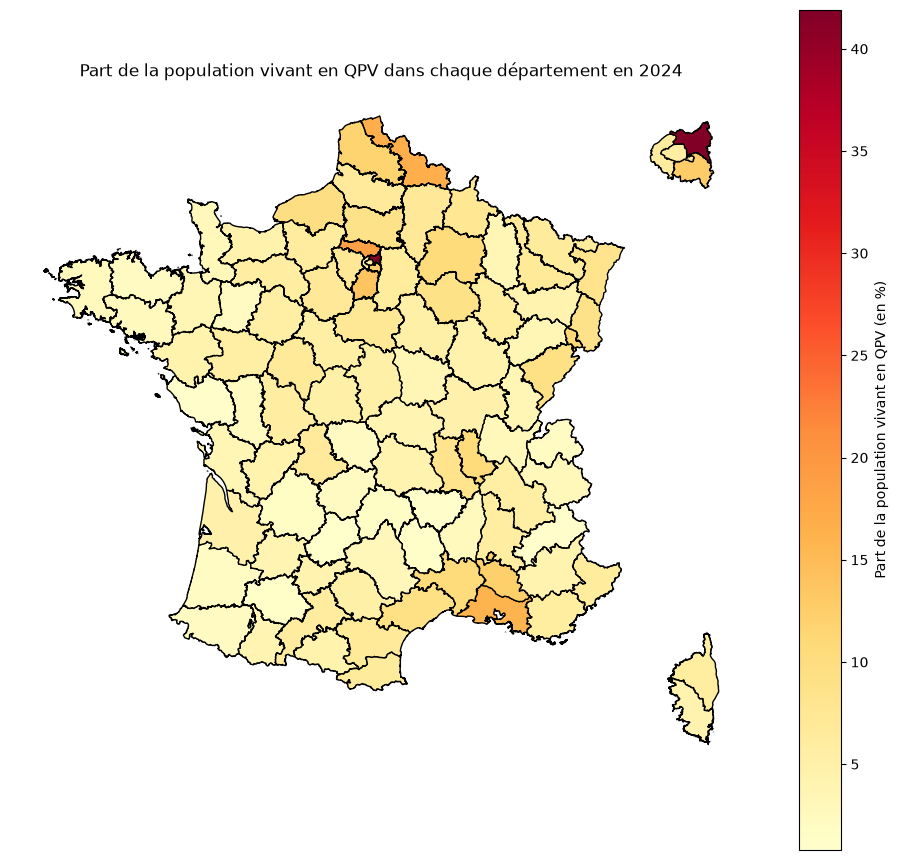

In [6]:
## Importation des données

data_QPV = pd.read_csv("/home/onyxia/Projet_Python_2A/QPV_data/Départements/part_population_QPV_département.csv", sep=";", skiprows=2, dtype={"Code" : str})

## Nettoyage des données

data_QPV = data_QPV[~data_QPV["Code"].str.startswith("97")] #On retire les Outre-mer

## Création d'une carte

url_fond_de_carte = ("https://minio.lab.sspcloud.fr/projet-cartiflette/production/"
       "provider=IGN/dataset_family=ADMINEXPRESS/"
       "source=EXPRESS-COG-CARTO-TERRITOIRE/year=2022/"
       "administrative_level=DEPARTEMENT/crs=4326/FRANCE_ENTIERE=France/"
       "vectorfile_format=geojson/territory=metropole/simplification=50/raw.geojson")

départements = gpd.read_file(url_fond_de_carte)

départements = départements[~départements["INSEE_DEP"].str.startswith("97")]
départements = départements.to_crs(2154)

carte = départements.merge(data_QPV, left_on="INSEE_DEP", right_on="Code", how="left")

petite_couronne = carte[carte["INSEE_DEP"].isin(["75", "92", "93", "94"])]

variable = "QPV - Quartiers prioritaires de la politique de la ville 2024 : Part de la population municipale résidant en QPV"

fig = plt.figure(figsize=(16,10))

ax1 = fig.add_axes([0.03, 0.08, 0.58, 0.84])
ax2 = fig.add_axes([0.35, 0.65, 0.20, 0.25])

xmin, ymin, xmax, ymax = petite_couronne.total_bounds
ax2.set_xlim(xmin-50000, xmax+50000)
ax2.set_ylim(ymin-50000, ymax+50000)

vmin = carte[variable].min()
vmax = carte[variable].max()

graphe = carte.plot(column=variable, ax=ax1, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black", legend=True, legend_kwds={"label": "Part de la population vivant en QPV (en %)"})
petite_couronne.plot(column=variable, ax=ax2, cmap="YlOrRd", vmin=vmin, vmax=vmax, edgecolor="black")
graphe.set_axis_off()
graphe.set_title("Part de la population vivant en QPV dans chaque département en 2024")
ax2.set_axis_off()
plt.show()

Ici, on remarque que la majorité des départements ont une population vivant en QPV assez faible par rapport à la population départementale. Quelques départements se démarquent par des taux assez élevés : La Seine-Saint-Denis, la Val-d'Oise, le Nord et les Bouches-du-Rhône. 
Ceci étant dit, nous allons pouvoir entrer dans le vif du sujet et comparer les départements ayant connu des épisodes d'émeutes à ceux n'en ayant pas connu depuis mars 2026.

Comparaison des départements touchés par les émeutes avec les départements non touchés depuis mars 2026

Comme on peut le deviner avec tout ce qui précède, nous allons essayer de voir si le taux d'inactivité chez les jeunes et la part de la population vivant en QPV sont de bons indicateurs pour "prédire" les émeutes en 2026. Ils s'étaient avérés être d'assez bons indicateurs en 2005 et en 2023. Nous cherchons donc à savoir si cela est toujours d'actualité. 
Nous allons travailler avec des histogrammes séparés entre les départements touchés et les départements non touchés.
Les taux d'inactivité ont été divisés en tranches égales et le graphique ci-après montre le nombre de départements touchés ou non touchés qui ont un taux d'inactivité des jeunes dans chaque tranche. 

/tmp/ipykernel_6290/1948425247.py:3: Pandas4Warning: reindexing with a fill_value that cannot be held by the original dtype is deprecated. Explicitly cast to a common dtype (in this case object) instead.
  émeutes_agrégé = émeutes_agrégé.reindex(departements["INSEE_DEP"], fill_value="0") #On complète avec 0 émeutes pour les départements non concernés
/tmp/ipykernel_6290/1948425247.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
/tmp/ipykernel_6290/1948425247.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


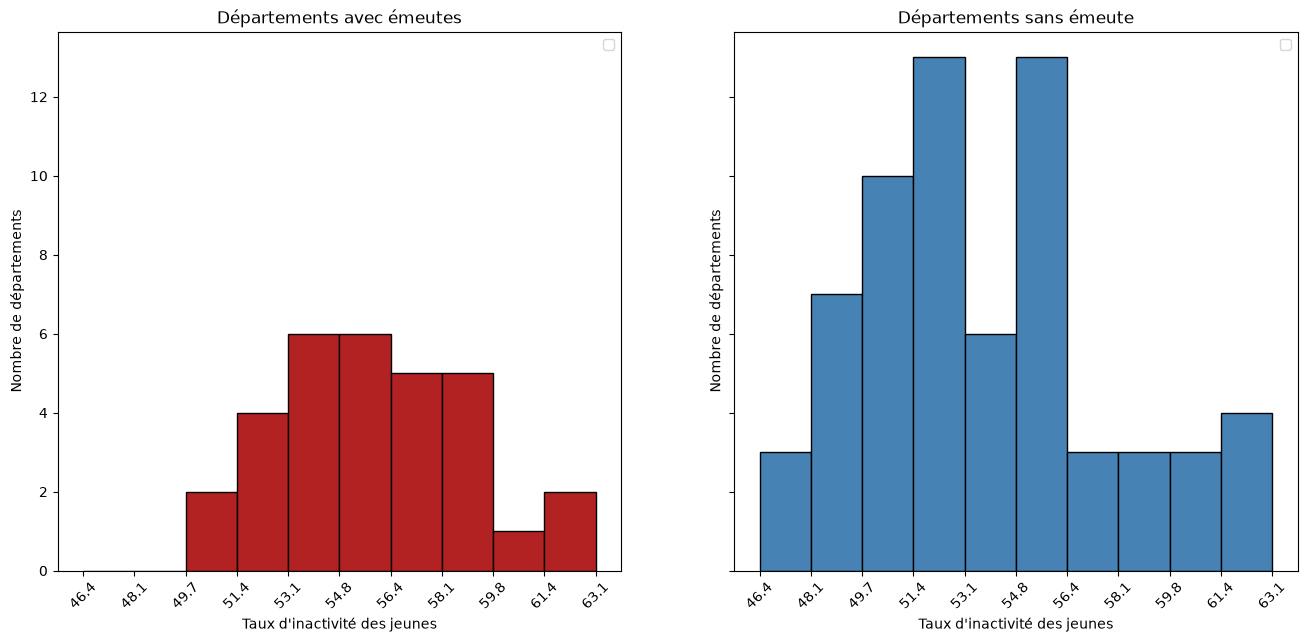

In [7]:
## Jointure entre toutes les données et histogrammes
émeutes_agrégé = émeutes_agrégé.to_frame()
émeutes_agrégé = émeutes_agrégé.reindex(departements["INSEE_DEP"], fill_value="0") #On complète avec 0 émeutes pour les départements non concernés
émeutes_agrégé = émeutes_agrégé.reset_index() #On met au format DataFrame pour pouvoir faire les jointures

data1 = émeutes_agrégé.merge(data_inactivité, left_on="INSEE_DEP", right_on="Code", how="left")
data_tout = data1.merge(data_QPV, on="Code", how="left")

data_émeutes = data_tout[data_tout["count"].astype(float)>0]
data_non_émeutes = data_tout[data_tout["count"].astype(float)==0]

#On fait l'histogramme sur l'inactivité

bins = np.linspace(data_tout["Taux d'inactivité chez les jeunes"].min(), data_tout["Taux d'inactivité chez les jeunes"].max(), 11)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

ax1.hist(data_émeutes["Taux d'inactivité chez les jeunes"], bins=bins, color="firebrick", edgecolor="black")
ax1.set_title("Départements avec émeutes")

ax2.hist(data_non_émeutes["Taux d'inactivité chez les jeunes"], bins=bins, color="steelblue", edgecolor="black")
ax2.set_title("Départements sans émeute")

for ax in (ax1, ax2):
    ax.set_xticks(bins)
    ax.set_xticklabels([f"{b:.1f}" for b in bins], rotation=45)
    ax.set_xlabel("Taux d'inactivité des jeunes")
    ax.set_ylabel("Nombre de départements")
    ax.legend()

plt.show()

Interprétation histogramme inactivité

Passons maintenant à la part de la population vivant dans les QPV. Pour des raisons des lisibilité des graphiques, nous avons retiré la donnée sur la Seine-Saint-Denis, où la part de la population vivant en QPV est très élevée par rapport aux autres départements, ce qui rangeait tous les autres départements dans les deux tranches les plus basses.
On obtient le duo d'histogrammes ci-dessous : 

/tmp/ipykernel_6290/2395114192.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
/tmp/ipykernel_6290/2395114192.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


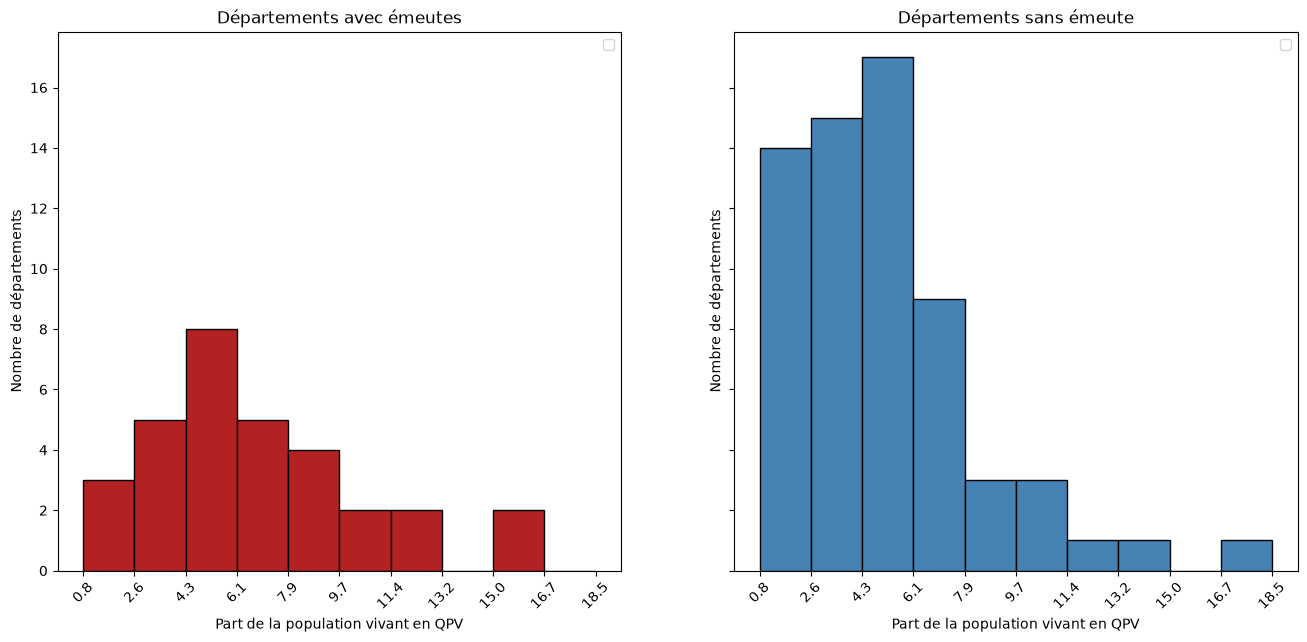

In [8]:
# On fait de même un histogramme avec les QPV
data_tout = data_tout[~data_tout["INSEE_DEP"].isin(["93"])] #On supprime le 93 qui rend le graphe peu exploitable
variable = "QPV - Quartiers prioritaires de la politique de la ville 2024 : Part de la population municipale résidant en QPV"

bins1 = np.linspace(data_tout[variable].min(), data_tout[variable].max(), 11)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

ax1.hist(data_émeutes[variable], bins=bins1, color="firebrick", edgecolor="black")
ax1.set_title("Départements avec émeutes")

ax2.hist(data_non_émeutes[variable], bins=bins1, color="steelblue", edgecolor="black")
ax2.set_title("Départements sans émeute")

for ax in (ax1, ax2):
    ax.set_xticks(bins1)
    ax.set_xticklabels([f"{b:.1f}" for b in bins1], rotation=45)
    ax.set_xlabel("Part de la population vivant en QPV")
    ax.set_ylabel("Nombre de départements")
    ax.legend()

plt.show()

Interprétation histogramme QPV